In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

# PUNTO 1


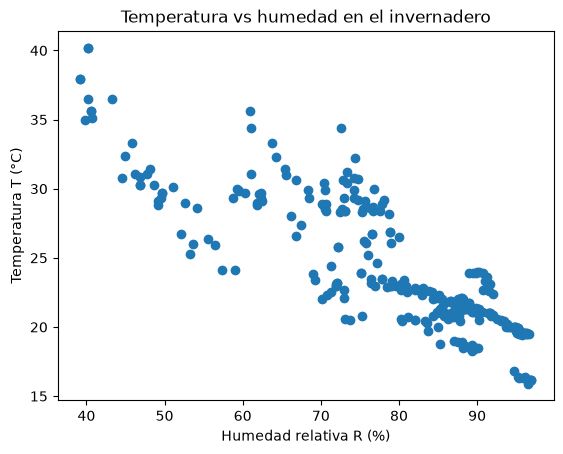

Correlación entre T y R = -0.8650
Temperatura mínima = 15.9 y máxima = 40.2
Humedad mínima = 39.2 y máxima = 96.9


In [2]:
# PARTE A punto 1
datos = pd.read_csv('data/greenhouse.txt', header=None, sep=r'\s+', names=['T', 'R'])
T = np.array(datos['T'])
R = np.array(datos['R'])

plt.scatter(R, T)
plt.xlabel('Humedad relativa R (%)')
plt.ylabel('Temperatura T (°C)')
plt.title('Temperatura vs humedad en el invernadero')
plt.show()

# Calculos para el analisis
#Coeficiente de correlación entre temperatura y humedad
correlacion = np.corrcoef(T, R)[0, 1]
print(f"Correlación entre T y R = {correlacion:.4f}")

#Mínimo y máximo de cada columna
print(f"Temperatura mínima = {T.min()} y máxima = {T.max()}")
print(f"Humedad mínima = {R.min()} y máxima = {R.max()}")

beta0 = 46.4062
beta1 = -0.2835


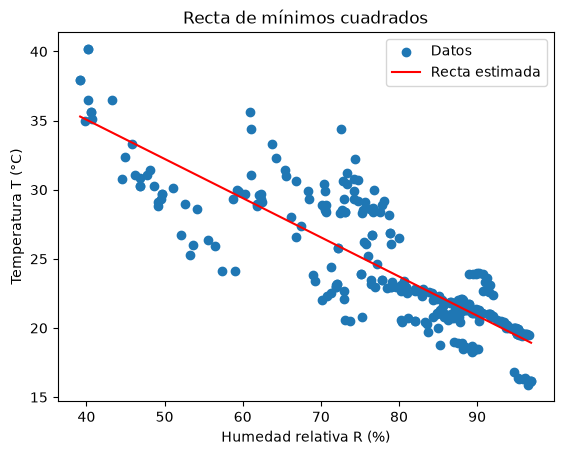

In [3]:
# PARTE B punto 1

#Matriz H con una columna de unos (para beta0) y otra con la humedad (para beta1)
H = np.column_stack((np.ones(len(R)), R))

#Se resuelve por mínimos cuadrados con beta = (H^T H)^{-1} H^T T
beta = np.linalg.inv(H.T @ H) @ H.T @ T
beta0, beta1 = beta
print(f"beta0 = {beta0:.4f}")
print(f"beta1 = {beta1:.4f}")

#Se grafica la recta estimada sobre los datos
R_linea = np.linspace(R.min(), R.max(), 100)
plt.scatter(R, T, label='Datos')
plt.plot(R_linea, beta0 + beta1*R_linea, color='red', label='Recta estimada')
plt.xlabel('Humedad relativa R (%)')
plt.ylabel('Temperatura T (°C)')
plt.legend()
plt.title('Recta de mínimos cuadrados')
plt.show()

In [4]:
# PARTE C punto 1

#Residuos, o sea la diferencia entre la temperatura medida y la que predice la recta
residuos = T - (beta0 + beta1*R)
sigma = np.std(residuos, ddof=2)
umbral = 2*sigma
print(f"Desviación estándar de los residuos = {sigma:.4f}")
print(f"Umbral (2 sigma) = {umbral:.4f}")

#Una medición es anómala si su residuo supera el umbral
def es_anomalo(T_nuevo, R_nuevo):
    residuo = T_nuevo - (beta0 + beta1*R_nuevo)
    return np.abs(residuo) > umbral

#Como referencia, se mira qué fracción de los datos originales marcaría la regla
print(f"Fracción de datos originales marcados como anómalos = {np.mean(es_anomalo(T, R)):.3f}")

Desviación estándar de los residuos = 2.4664
Umbral (2 sigma) = 4.9329
Fracción de datos originales marcados como anómalos = 0.063


Anómalas = 336
Típicas = 164


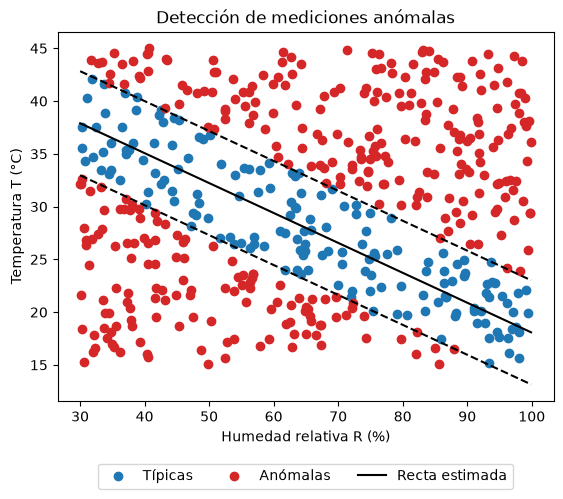

Por encima de la banda = 208
Por debajo de la banda = 128
Humedad >= 80%, anómalas por encima = 98
Humedad >= 80%, anómalas por debajo = 5
T >= 35 y R >= 80, total = 57, anómalas = 57
Humedad entre 30% y 50%, anómalas por debajo = 75
Humedad entre 30% y 50%, anómalas por encima = 24
T <= 22 y R <= 50, total = 33, anómalas = 33
Correlación en los datos nuevos = 0.0051
Fuera del rango de los datos originales = 174


In [5]:
# PARTE D punto 1
nuevos = pd.read_csv('data/datosNuevos.txt', header=None, sep=r'\s+', names=['T', 'R'])
T_n = np.array(nuevos['T'])
R_n = np.array(nuevos['R'])

#Se aplica la regla a todas las mediciones nuevas
anomalo = es_anomalo(T_n, R_n)
print(f"Anómalas = {anomalo.sum()}")
print(f"Típicas = {(~anomalo).sum()}")

#Puntos típicos en azul y anómalos en rojo, junto con la recta y la banda de aceptación (más y menos el umbral)
R_linea2 = np.linspace(R_n.min(), R_n.max(), 100)
plt.scatter(R_n[~anomalo], T_n[~anomalo], color='tab:blue', label='Típicas')
plt.scatter(R_n[anomalo], T_n[anomalo], color='tab:red', label='Anómalas')
plt.plot(R_linea2, beta0 + beta1*R_linea2, color='black', label='Recta estimada')
plt.plot(R_linea2, beta0 + beta1*R_linea2 + umbral, 'k--')
plt.plot(R_linea2, beta0 + beta1*R_linea2 - umbral, 'k--')
plt.xlabel('Humedad relativa R (%)')
plt.ylabel('Temperatura T (°C)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.title('Detección de mediciones anómalas')
plt.show()

#calculos adicionales para el análisis de los datos nuevos
#Residuo de cada medición nueva respecto a la recta
residuo_n = T_n - (beta0 + beta1*R_n)

#Anómalas por encima y por debajo de la banda
por_encima = residuo_n > umbral
por_debajo = residuo_n < -umbral
print(f"Por encima de la banda = {por_encima.sum()}")
print(f"Por debajo de la banda = {por_debajo.sum()}")

#Mediciones con humedad de 80% o más
alta = R_n >= 80
print(f"Humedad >= 80%, anómalas por encima = {(alta & por_encima).sum()}")
print(f"Humedad >= 80%, anómalas por debajo = {(alta & por_debajo).sum()}")

#Mediciones con 35 °C o más y humedad de 80% o más, y cuántas son anómalas
caso1 = (T_n >= 35) & (R_n >= 80)
print(f"T >= 35 y R >= 80, total = {caso1.sum()}, anómalas = {anomalo[caso1].sum()}")

#Mediciones con humedad entre 30% y 50%
baja = (R_n >= 30) & (R_n < 50)
print(f"Humedad entre 30% y 50%, anómalas por debajo = {(baja & por_debajo).sum()}")
print(f"Humedad entre 30% y 50%, anómalas por encima = {(baja & por_encima).sum()}")

#Mediciones con 22 °C o menos y humedad de 50% o menos, y cuántas son anómalas
caso2 = (T_n <= 22) & (R_n <= 50)
print(f"T <= 22 y R <= 50, total = {caso2.sum()}, anómalas = {anomalo[caso2].sum()}")

#Correlación entre T y R en los datos nuevos
print(f"Correlación en los datos nuevos = {np.corrcoef(T_n, R_n)[0, 1]:.4f}")

#Mediciones con temperatura o humedad fuera del rango de los datos originales
fuera = (T_n < T.min()) | (T_n > T.max()) | (R_n < R.min()) | (R_n > R.max())
print(f"Fuera del rango de los datos originales = {fuera.sum()}")

# PUNTO 2

In [2]:
df = pd.read_csv('data/datosToy.txt', header=None, delim_whitespace=True, names=['x', 'y'])
df.head()

C:\Users\jlpar\AppData\Local\Temp\ipykernel_16876\3704442140.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('data/datosToy.txt', header=None, delim_whitespace=True, names=['x', 'y'])


,x,y
0,-1.000000,18.966314
1,-0.997998,20.079921
2,-0.995996,18.209926
3,-0.993994,18.934774
4,-0.991992,18.512598


Valores de los parámetros óptimos para c=0: w0=6.346617, w1=-5.248010
Valores de los parámetros óptimos para c=1: w0=6.340276, w1=-5.232344
Valores de los parámetros óptimos para c=10: w0=6.283779, w1=-5.095452
Valores de los parámetros óptimos para c=1000: w0=3.173308, w1=-1.313972


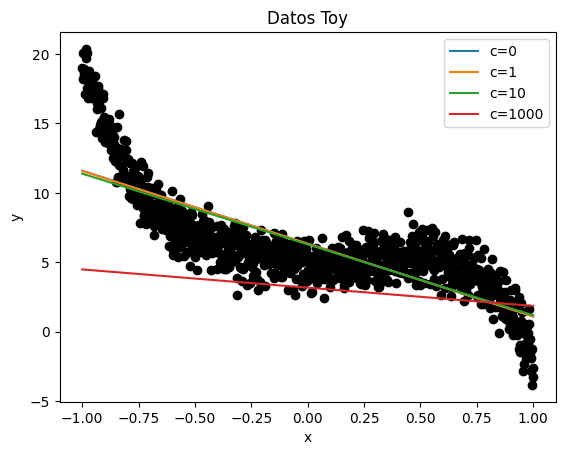

In [7]:
x=np.array(df['x'])
y=np.array(df['y'])
c= np.array([0,1,10,1000])


#Funcion auxiliar que retorna la matriz H
def matriz_H(n,x):
    #Se crea una matriz rellena de ceros inicialmente
    H=np.zeros((len(x),n+1))

    #Se recorre cada valor de la variable independiente
    for i in range(len(x)):

        #Se recorre n veces correspondiente al grado polinomico
        for j in range(n+1):
            #Se actualiza cada casilla de la matriz elevando el termino de la variable independiente a la potencia del grado polinomico correspondiente
            H[i,j]=x[i]**j
    return H

#Funcion auxiliar que retorna los parámetros óptimos utilizando la formula propuesta utilizando regularización: (H^TH + c*I)^{-1}H^Ty
def wopt(H,y,c):
    w=np.linalg.inv(H.T@H + c*np.eye(H.shape[1]))@H.T@y
    return w


# PARTE A punto 2

#creación de la matriz H
h_t = matriz_H(1, x)

for i in range(len(c)):
    #cálculo de los parámetros óptimos
    w_t = wopt(h_t, y, c[i])
    #Valor de los parámetros óptimos para cada valor de c
    print(f'Valores de los parámetros óptimos para c={c[i]}: w0={w_t[0]:.6f}, w1={w_t[1]:.6f}')
    #Arreglo de predicciones haciendo el producto de la matriz H con los parámetros óptimos
    array = h_t@w_t
    plt.plot(x,array, label=f'c={c[i]}')

plt.scatter(x,y, color='black')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Datos Toy')
plt.show()

Valores de los parámetros óptimos para c=0: w0=5.058024, w1=-5.248010, w2=3.858054
Valores de los parámetros óptimos para c=1: w0=5.060986, w1=-5.232344, w2=3.834034
Valores de los parámetros óptimos para c=10: w0=5.079963, w1=-5.095452, w2=3.640276
Valores de los parámetros óptimos para c=1000: w0=2.968508, w1=-1.313972, w2=1.226350


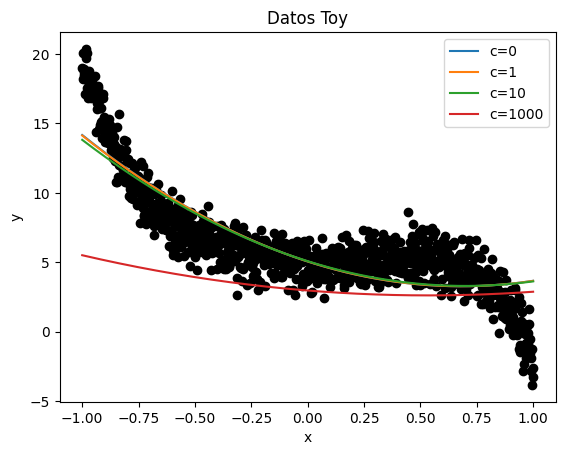

In [8]:

# PARTE B punto 2 - se repite lo mismo de la parte A pero ahora el grado es 2
h2_t = matriz_H(2, x)
for i in range(len(c)):
    w2_t = wopt(h2_t, y, c[i])
    print(f'Valores de los parámetros óptimos para c={c[i]}: w0={w2_t[0]:.6f}, w1={w2_t[1]:.6f}, w2={w2_t[2]:.6f}')
    array = h2_t@w2_t
    plt.plot(x,array, label=f'c={c[i]}')

plt.scatter(x,y, color='black')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Datos Toy')
plt.show()

Valores de los parámetros óptimos para c=0: w0=5.058024, w1=-44.831592, w2=3.858054, w3=46.935783
Valores de los parámetros óptimos para c=1: w0=5.060986, w1=-20.150343, w2=3.834034, w3=17.741808
Valores de los parámetros óptimos para c=10: w0=5.079963, w1=-5.677947, w2=3.640276, w3=0.711366
Valores de los parámetros óptimos para c=1000: w0=2.968508, w1=-1.125551, w2=1.226350, w3=-0.892333


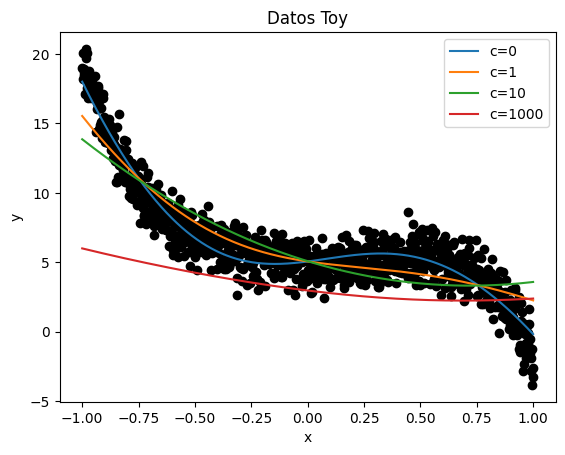

In [9]:
# PARTE C punto 2

#A la matriz H obtenida en la parte B se le agrega una columna con la función tanh de la variable independiente 
h2_t2 = np.column_stack((h2_t, np.tanh(x)))
for i in range(len(c)):
    w2_t2 = wopt(h2_t2, y, c[i])
    print(f'Valores de los parámetros óptimos para c={c[i]}: w0={w2_t2[0]:.6f}, w1={w2_t2[1]:.6f}, w2={w2_t2[2]:.6f}, w3={w2_t2[3]:.6f}')
    array = h2_t2@w2_t2
    plt.plot(x,array, label=f'c={c[i]}')


plt.scatter(x,y, color='black')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Datos Toy')
plt.show()

# PUNTO 3

Puntos con etiqueta 1 = 3794
Puntos con etiqueta 0 = 6206


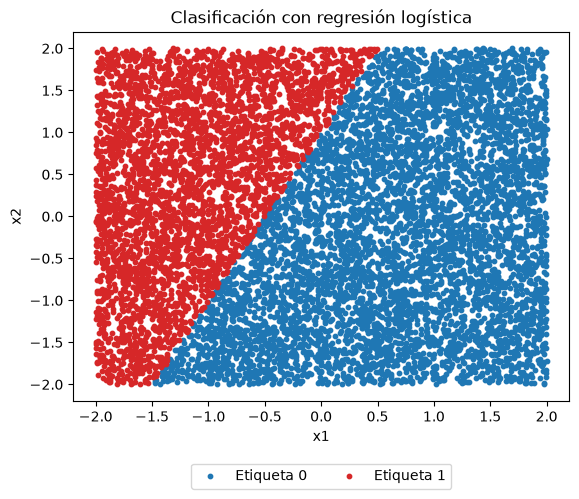

In [6]:
# PARTE ÚNICA punto 3
datosNN = pd.read_csv('data/datosNN.txt', header=None, sep=r'\s+', names=['x1', 'x2'])
X = np.array(datosNN)

w = np.array([-2, 1])
b = -1

#Función sigmoide
def sigmoide(z):
    return 1/(1 + np.exp(-z))

#Se aplica la regla de decisión a todos los puntos con y = sigmoide(w^T x + b)
y = sigmoide(X @ w + b)

#Etiqueta 1 si y > 0.5 y etiqueta 0 en caso contrario
etiquetas = (y > 0.5).astype(int)
print(f"Puntos con etiqueta 1 = {np.sum(etiquetas == 1)}")
print(f"Puntos con etiqueta 0 = {np.sum(etiquetas == 0)}")

plt.scatter(X[etiquetas == 0, 0], X[etiquetas == 0, 1], color='tab:blue', s=10, label='Etiqueta 0')
plt.scatter(X[etiquetas == 1, 0], X[etiquetas == 1, 1], color='tab:red', s=10, label='Etiqueta 1')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.title('Clasificación con regresión logística')
plt.show()

# PUNTO 4


In [7]:
# PARTE A punto 4

#Pesos y sesgos de cada neurona según la Tabla 1, cada neurona recibe 2 entradas
w1 = np.array([0.1188, -2.1436])
b1 = 0.7065
w2 = np.array([1.6878, 0.2615])
b2 = -1.0121
w3 = np.array([-0.4082, -0.8420])
b3 = 0
w4 = np.array([1.1433, 1.9843])
b4 = -0.1435
w5 = np.array([-1.3052, 1.6268])
b5 = -2.1021

#Función de activación ReLU, deja pasar z si es positivo y devuelve 0 si es negativo
def relu(z):
    return max(0, z)

#Función de activación sigmoide de la neurona de salida
def sigmoide_red(z):
    return 1/(1 + np.exp(-z))

#Rutina que propaga un vector x = [x1, x2] por la red de la Figura 1 y retorna la salida y
def propagar(x):
    #Primera capa oculta: las neuronas 1 y 2 reciben directamente a x1 y x2
    h1 = relu(np.dot(w1, x) + b1)
    h2 = relu(np.dot(w2, x) + b2)
    #Segunda capa oculta: las neuronas 3 y 4 reciben las salidas de las neuronas 1 y 2
    h_capa1 = np.array([h1, h2])
    h3 = relu(np.dot(w3, h_capa1) + b3)
    h4 = relu(np.dot(w4, h_capa1) + b4)
    #Neurona de salida: la neurona 5 recibe las salidas de las neuronas 3 y 4
    h_capa2 = np.array([h3, h4])
    y_salida = sigmoide_red(np.dot(w5, h_capa2) + b5)
    return y_salida

#Prueba de la rutina con un vector de ejemplo
x_prueba = np.array([1, -1])
print(f"Salida de la red para x = {x_prueba}: y = {propagar(x_prueba):.4f}")

Salida de la red para x = [ 1 -1]: y = 0.9893


Número de puntos = 10000
Puntos con etiqueta 1 = 5944
Puntos con etiqueta 0 = 4056


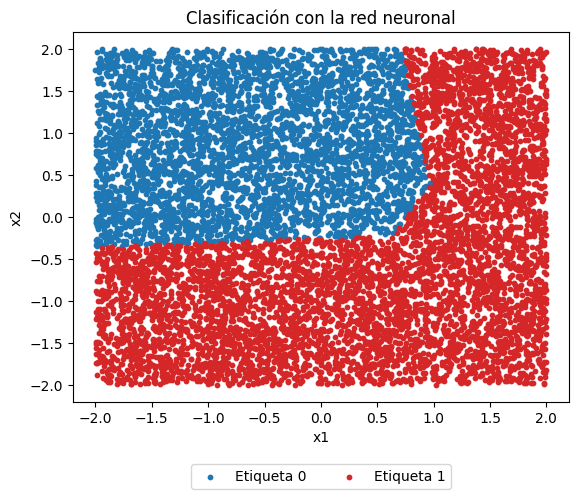

In [8]:
# PARTE B punto 4
datos4 = pd.read_csv('data/datosNN.txt', header=None, sep=r'\s+', names=['x1', 'x2'])
X_red = np.array(datos4)

#Se pasa cada vector de datosNN.txt por la red y se guarda su salida
y_red = np.array([propagar(x_i) for x_i in X_red])

#Etiqueta 1 si la salida es mayor a 0.5 y etiqueta 0 en caso contrario
etiquetas_red = (y_red > 0.5).astype(int)
print(f"Número de puntos = {len(X_red)}")
print(f"Puntos con etiqueta 1 = {np.sum(etiquetas_red == 1)}")
print(f"Puntos con etiqueta 0 = {np.sum(etiquetas_red == 0)}")

plt.scatter(X_red[etiquetas_red == 0, 0], X_red[etiquetas_red == 0, 1], color='tab:blue', s=10, label='Etiqueta 0')
plt.scatter(X_red[etiquetas_red == 1, 0], X_red[etiquetas_red == 1, 1], color='tab:red', s=10, label='Etiqueta 1')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.title('Clasificación con la red neuronal')
plt.show()

Valor máximo de la neurona 3 en todos los datos = 0.0
La salida es mayor a 0.5 cuando h4 > 1.2922
Lo que equivale a 1.1433*h1 + 1.9843*h2 > 1.4357
Salida de la red cuando h4 = 0: y = 0.1089
h1 > 0 y h2 > 0: puntos = 1801, con etiqueta 1 = 1727
solo h1 > 0: puntos = 3985, con etiqueta 1 = 3016
solo h2 > 0: puntos = 1647, con etiqueta 1 = 1201
h1 = 0 y h2 = 0: puntos = 2567, con etiqueta 1 = 0
Puntos con 0.4 < y < 0.6 = 568


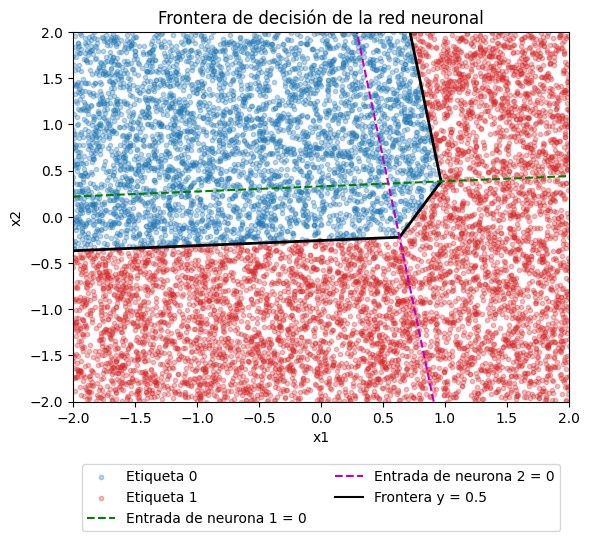

In [9]:
# PARTE C punto 4

#Salidas de las neuronas 1 y 2 para todos los puntos, que son las entradas de la segunda capa
h1_red = np.maximum(0, X_red @ w1 + b1)
h2_red = np.maximum(0, X_red @ w2 + b2)

#Salida de la neurona 3, como w3 tiene ambos pesos negativos y b3 = 0 su entrada nunca es positiva
h3_red = np.maximum(0, w3[0]*h1_red + w3[1]*h2_red + b3)
print(f"Valor máximo de la neurona 3 en todos los datos = {h3_red.max()}")

#Umbral que debe superar la neurona 4 para que y > 0.5, sale de despejar w5[1]*h4 + b5 > 0
umbral_h4 = -b5/w5[1]
print(f"La salida es mayor a 0.5 cuando h4 > {umbral_h4:.4f}")
print(f"Lo que equivale a 1.1433*h1 + 1.9843*h2 > {umbral_h4 - b4:.4f}")

#Salida mínima de la red, que ocurre cuando h4 = 0
print(f"Salida de la red cuando h4 = 0: y = {sigmoide_red(b5):.4f}")

#Cuántos puntos y cuántos con etiqueta 1 hay según qué neuronas de la primera capa estén activas
activa1 = h1_red > 0
activa2 = h2_red > 0
for nombre, region in [('h1 > 0 y h2 > 0', activa1 & activa2), ('solo h1 > 0', activa1 & ~activa2),
                       ('solo h2 > 0', ~activa1 & activa2), ('h1 = 0 y h2 = 0', ~activa1 & ~activa2)]:
    print(f"{nombre}: puntos = {region.sum()}, con etiqueta 1 = {etiquetas_red[region].sum()}")

#Puntos con salida cercana a 0.5, es decir con clasificación poco segura
print(f"Puntos con 0.4 < y < 0.6 = {np.sum((y_red > 0.4) & (y_red < 0.6))}")

#Se evalúa la red en una malla fina para dibujar la frontera de decisión (donde y = 0.5)
x1_malla, x2_malla = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-2, 2, 400))
y_malla = np.array([propagar(np.array([x1_val, x2_val])) for x1_val, x2_val in zip(x1_malla.ravel(), x2_malla.ravel())]).reshape(x1_malla.shape)

plt.scatter(X_red[etiquetas_red == 0, 0], X_red[etiquetas_red == 0, 1], color='tab:blue', s=10, alpha=0.3, label='Etiqueta 0')
plt.scatter(X_red[etiquetas_red == 1, 0], X_red[etiquetas_red == 1, 1], color='tab:red', s=10, alpha=0.3, label='Etiqueta 1')
#Frontera de decisión de la red
plt.contour(x1_malla, x2_malla, y_malla, levels=[0.5], colors='black', linewidths=2)
#Rectas donde se apagan las neuronas 1 y 2 (su entrada vale 0)
x1_linea = np.linspace(-2, 2, 100)
x2_linea = np.linspace(-2, 2, 100)
#Neurona 1: w1[0]*x1 + w1[1]*x2 + b1 = 0, se despeja x2
plt.plot(x1_linea, (w1[0]*x1_linea + b1)/(-w1[1]), 'g--', label='Entrada de neurona 1 = 0')
#Neurona 2: w2[0]*x1 + w2[1]*x2 + b2 = 0, se despeja x1
plt.plot((w2[1]*x2_linea + b2)/(-w2[0]), x2_linea, 'm--', label='Entrada de neurona 2 = 0')
plt.plot([], [], color='black', label='Frontera y = 0.5')
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.title('Frontera de decisión de la red neuronal')
plt.show()

# PUNTO 5

In [3]:
datos5 = pd.read_csv('data/coordenadasPacientes.txt', header=None, delim_whitespace=True, names=['x', 'y'])
datos5.head()

C:\Users\jlpar\AppData\Local\Temp\ipykernel_24032\4056743067.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  datos5 = pd.read_csv('data/coordenadasPacientes.txt', header=None, delim_whitespace=True, names=['x', 'y'])


,x,y
0,3.215775,5.853221
1,4.486974,6.199002
2,2.980549,9.141662
3,5.253936,5.998349
4,3.432972,6.490219


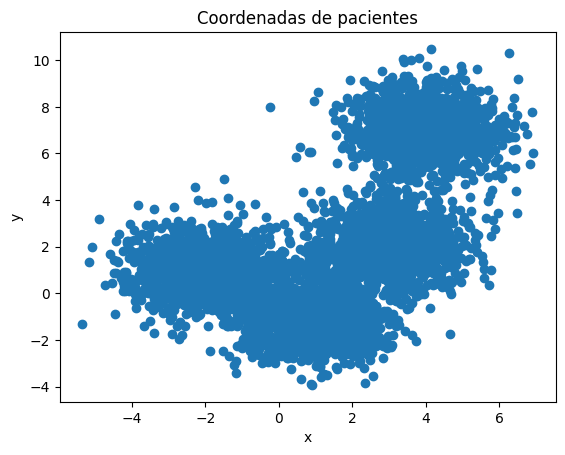

In [ ]:
#PARTE A punto 3
x=np.array(datos5['x'])
y=np.array(datos5['y'])

plt.scatter(x,y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Coordenadas de pacientes')
plt.show()

Centroides sin random: [[ 3.04868456  2.07254448]
 [-2.04916997  0.9629026 ]
 [ 0.99945004 -1.05255402]
 [ 3.97946787  7.02852811]]
Inercia sin random: 9643.872905359814


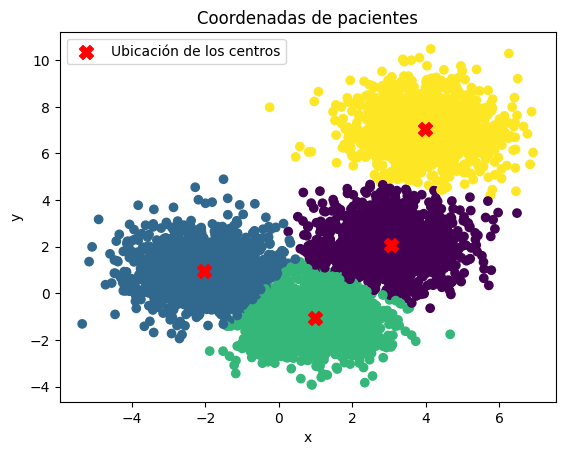

In [29]:

#PARTE B punto 3

#Se implementa el algoritmo KMeans para agrupar los datos en 4 clusters
#Primero, se crea un objeto KMeans con el número de clusters y una semilla aleatoria. 
modelo = KMeans(n_clusters=4, random_state=0)

#Se crea una matriz con las coordenadas de los pacientes, donde cada fila representa un paciente y cada columna representa una coordenada (x o y).
matriz = np.column_stack((x,y))

#se entrena el modelo con la matriz de coordenadas de los pacientes
modelo.fit(matriz)

#se predicen los clusters a los que pertenecen cada uno de los pacientes y se obtienen los centroides de cada cluster
pred = modelo.predict(matriz)
centroides = modelo.cluster_centers_
print(f"Centroides sin random: {centroides}")
#Se grafican los puntos y los centroides(en el contexto los centroides serian la ubicación de los centros de atención) de cada cluster
inercia = modelo.inertia_
print(f"Inercia sin random: {inercia}")
plt.scatter(x,y, c=pred)
plt.scatter(centroides[:,0], centroides[:,1], c='red', marker='X', s=100, label='Ubicación de los centros')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Coordenadas de pacientes')
plt.show()

Centroides con random: [[ 0.98603623 -1.05785586]
 [ 3.04231749  2.06338028]
 [-2.05485688  0.96998385]
 [ 3.97966884  7.02643412]]
Inercia con random: 9643.769690878351


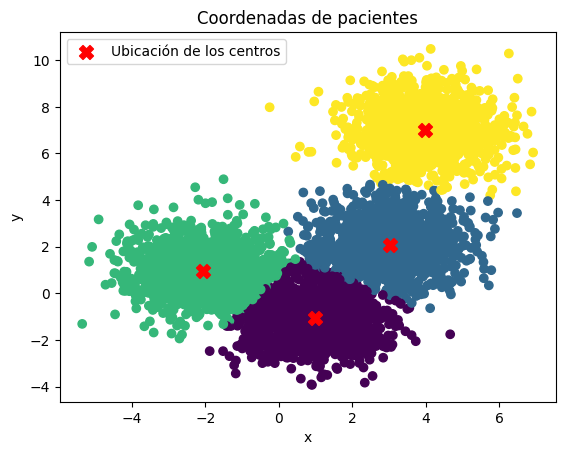

In [30]:
#PARTE C punto 3, igual a la parte B pero se cambia la condición de inicializacion a random, lo que significa que los centroides iniciales se seleccionan aleatoriamente a partir de los datos en lugar de usar el método predeterminado 'k-means++'.

modelo2 = KMeans(n_clusters=4, random_state=0, init='random')


matriz = np.column_stack((x,y))

modelo2.fit(matriz)
pred2 = modelo2.predict(matriz)
centroides2 = modelo2.cluster_centers_
print(f"Centroides con random: {centroides2}")
inercia2 = modelo2.inertia_
print(f"Inercia con random: {inercia2}")
plt.scatter(x,y, c=pred2)
plt.scatter(centroides2[:,0], centroides2[:,1], c='red', marker='X', s=100, label='Ubicación de los centros')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Coordenadas de pacientes')
plt.show()